# E-Commerce Sales & Customer Intelligence Analysis

## Business Objective

Analyse e-commerce transaction data to understand order flow, delivery
performance, product and seller reliability, geographic differences,
freight economics, and customer purchasing behaviour.

The analysis uses NumPy, Pandas, Matplotlib and Seaborn to turn the raw
transaction tables into data-driven business insights.

## Notebook Structure

1. Setup and data loading
2. Data quality checks
3. Order status overview
4. Delivery time analysis
5. On-time vs late delivery
6. Late deliveries by product category
7. Late deliveries by seller
8. Late deliveries by customer state
9. Monthly late-delivery trend
10. Freight and order value vs delivery performance
11. Customer purchase behaviour
12. Summary of findings

## 1. Setup and Data Loading

Imports, shared plot styling, and the four source tables used throughout the
notebook. Date columns are parsed on load, so no later type conversion is needed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

In [2]:
DATE_COLUMNS = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

orders = pd.read_csv("orders_dataset.csv", parse_dates=DATE_COLUMNS)
order_items = pd.read_csv("order_items_dataset.csv")
products = pd.read_csv("products_dataset.csv")
customers = pd.read_csv("customers_dataset.csv")

for name, df in [("orders", orders), ("order_items", order_items),
                 ("products", products), ("customers", customers)]:
    print(f"{name:12s} {df.shape}")

orders       (99441, 8)
order_items  (112650, 7)
products     (32951, 9)
customers    (99441, 5)


In [3]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


## 2. Data Quality Checks

Column types, missing values and duplicate rows in the orders table.

In [4]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 6.1 MB


In [5]:
quality = pd.DataFrame({
    "missing_count": orders.isnull().sum(),
    "missing_percentage": orders.isnull().mean() * 100,
})

quality[quality["missing_count"] > 0]

,missing_count,missing_percentage
order_approved_at,160,0.160899
order_delivered_carrier_date,1783,1.793023
order_delivered_customer_date,2965,2.981668


In [6]:
print("Duplicate order_id values:", orders["order_id"].duplicated().sum())
print("Fully duplicated rows:    ", orders.duplicated().sum())

Duplicate order_id values: 0
Fully duplicated rows:     0


## 3. Order Status Overview

How orders are spread across the lifecycle statuses, and how much of the book
is anything other than `delivered`.

In [7]:
status_summary = orders["order_status"].value_counts().to_frame("order_count")
status_summary["percentage"] = status_summary["order_count"] / len(orders) * 100

status_summary

,order_count,percentage
order_status,,
delivered,96478,97.020344
shipped,1107,1.113223
canceled,625,0.628513
unavailable,609,0.612423
invoiced,314,0.315765
processing,301,0.302692
created,5,0.005028
approved,2,0.002011


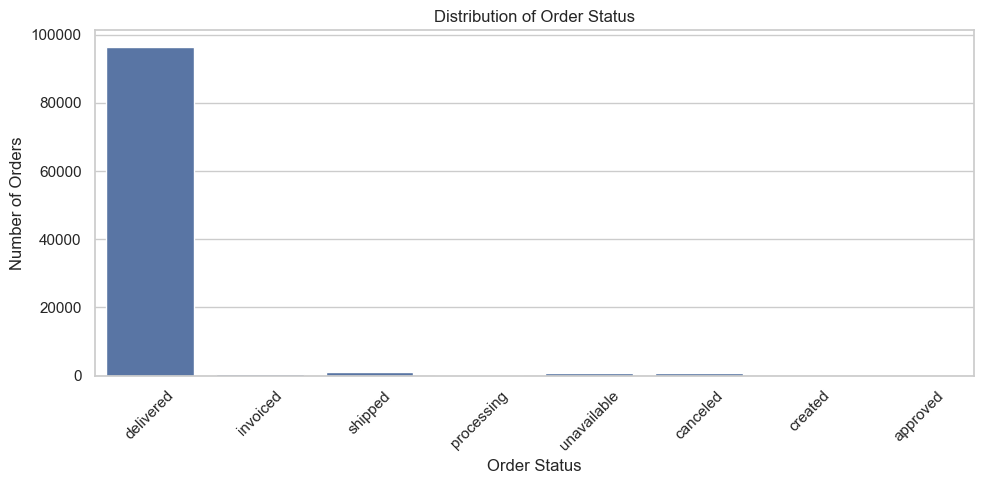

In [8]:
sns.countplot(data=orders, x="order_status")

plt.title("Distribution of Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
# Orders that never reached the customer, and the statuses they are stuck in
print("Share of orders not delivered:",
      round((orders["order_status"] != "delivered").mean() * 100, 2), "%")

orders[orders["order_delivered_customer_date"].isnull()]["order_status"].value_counts()

Share of orders not delivered: 2.98 %


order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

## 4. Delivery Time Analysis

Delivery time is measured from purchase to the moment the customer receives the
order.

In [10]:
orders["delivery_time_days"] = (
    orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

orders["delivery_time_days"].describe()

count    96476.000000
mean        12.558702
std          9.546530
min          0.533414
25%          6.766403
50%         10.217755
75%         15.720327
max        209.628611
Name: delivery_time_days, dtype: float64

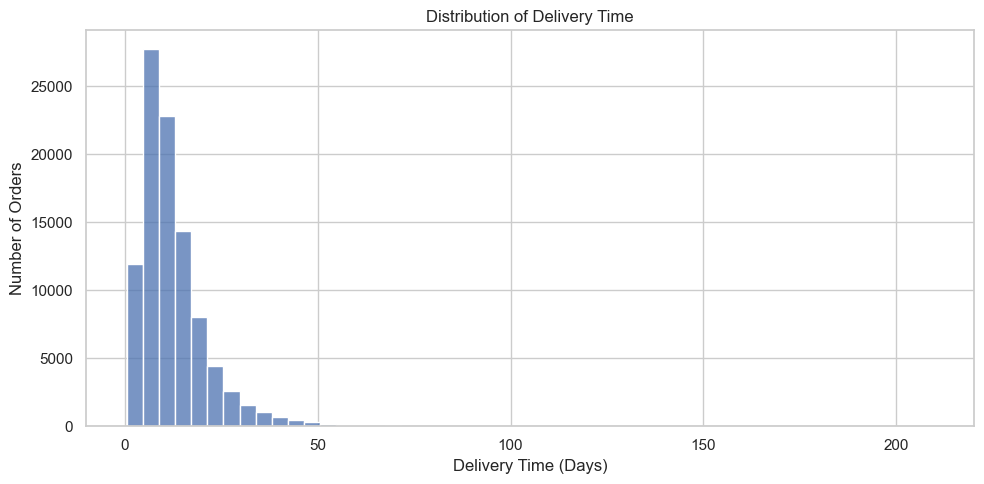

In [11]:
sns.histplot(data=orders, x="delivery_time_days", bins=50)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [12]:
orders[[
    "order_id", "order_status",
    "order_purchase_timestamp", "order_delivered_customer_date",
    "delivery_time_days",
]].sort_values("delivery_time_days", ascending=False).head(10)

,order_id,order_status,order_purchase_timestamp,order_delivered_customer_date,delivery_time_days
19590,ca07593549f1816d26a572e06dc1eab6,delivered,2017-02-21 23:31:27,2017-09-19 14:36:39,209.628611
55619,1b3190b2dfa9d789e1f14c05b647a14a,delivered,2018-02-23 14:57:35,2018-09-19 23:24:07,208.351759
61610,440d0d17af552815d15a9e41abe49359,delivered,2017-03-07 23:59:51,2017-09-19 15:12:50,195.634016
70307,2fb597c2f772eca01b1f5c561bf6cc7b,delivered,2017-03-08 18:09:02,2017-09-19 14:33:17,194.850174
89130,285ab9426d6982034523a855f55a885e,delivered,2017-03-08 22:47:40,2017-09-19 14:00:04,194.633611
38509,0f4519c5f1c541ddec9f21b3bddd533a,delivered,2017-03-09 13:26:57,2017-09-19 14:38:21,194.049583
11399,47b40429ed8cce3aee9199792275433f,delivered,2018-01-03 09:44:01,2018-07-13 20:51:31,191.463542
81401,2fe324febf907e3ea3f2aa9650869fa5,delivered,2017-03-13 20:17:10,2017-09-19 17:00:07,189.863160
54480,2d7561026d542c8dbd8f0daeadf67a43,delivered,2017-03-15 11:24:27,2017-09-19 14:38:18,188.134618
68769,c27815f7e3dd0b926b58552628481575,delivered,2017-03-15 23:23:17,2017-09-19 17:14:25,187.743843


## 5. On-Time vs Late Delivery

`delivered_orders` keeps only the orders that actually reached the customer and
is the base table for every delivery-performance section that follows.

Two measures are derived here and used consistently for the rest of the
notebook:

- `on_time_delivery` — arrived on or before the estimated delivery date.
- `delivery_delay_days` — how far past the estimate the order arrived, in
  fractional days, so an order that missed the promise by a few hours still
  registers as late.

Because the delay is fractional rather than truncated to whole days,
`delivery_delay_days > 0` is exactly the complement of `on_time_delivery`, and
every breakdown below reports the same late rate as the headline figure.

In [13]:
delivered_orders = orders[orders["order_delivered_customer_date"].notna()].copy()

delivered_orders["on_time_delivery"] = (
    delivered_orders["order_delivered_customer_date"]
    <= delivered_orders["order_estimated_delivery_date"]
)

delivered_orders["delivery_delay_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_estimated_delivery_date"]
).dt.total_seconds() / (24 * 60 * 60)

on_time_rate = delivered_orders["on_time_delivery"].mean() * 100

print("Delivered orders:  ", len(delivered_orders))
print("On-time rate:      ", round(on_time_rate, 2), "%")
print("Late delivery rate:", round(100 - on_time_rate, 2), "%")

Delivered orders:  

 96476
On-time rate:       91.89 %
Late delivery rate: 8.11 %


In [14]:
# How badly late are the orders that miss the promised date?
late_deliveries = delivered_orders[delivered_orders["delivery_delay_days"] > 0]

# Sanity check: the fractional delay agrees with the on-time flag
assert len(late_deliveries) == (~delivered_orders["on_time_delivery"]).sum()

late_deliveries["delivery_delay_days"].describe()

count    7827.000000
mean        9.552206
std        13.951700
min         0.002500
25%         1.867193
50%         5.807894
75%        11.822471
max       188.975081
Name: delivery_delay_days, dtype: float64

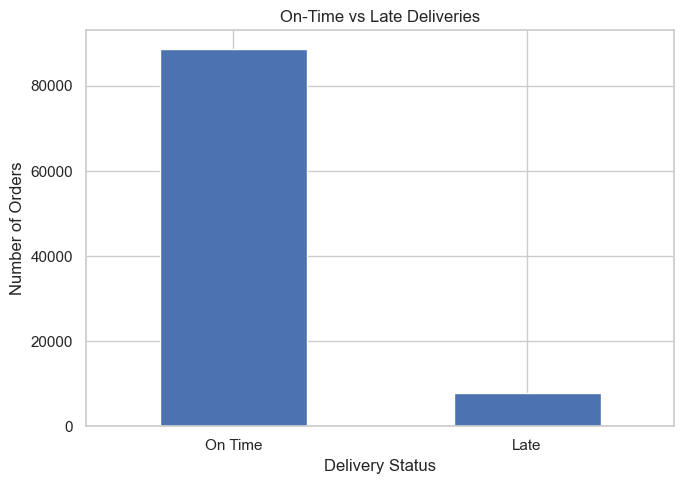

In [15]:
delivery_status = pd.Series({
    "On Time": int(delivered_orders["on_time_delivery"].sum()),
    "Late": len(late_deliveries),
})

delivery_status.plot(kind="bar", figsize=(7, 5))

plt.title("On-Time vs Late Deliveries")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Late Deliveries by Product Category

Order items are joined to their product category, then de-duplicated to one row
per (order, category) so a multi-item order is not counted repeatedly. Only
categories with at least 100 orders are ranked, so small categories cannot top
the list on a handful of orders.

In [16]:
MIN_CATEGORY_ORDERS = 100

order_products = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left",
)

category_delivery = delivered_orders.merge(
    order_products[["order_id", "product_category_name"]],
    on="order_id",
    how="left",
)

category_delivery["product_category_name"] = (
    category_delivery["product_category_name"].fillna("Unknown")
)

print("Product categories:", category_delivery["product_category_name"].nunique())

Product categories: 74


In [17]:
category_orders = category_delivery[
    ["order_id", "product_category_name", "delivery_delay_days"]
].drop_duplicates(subset=["order_id", "product_category_name"])

category_orders["is_late"] = category_orders["delivery_delay_days"] > 0

category_performance = (
    category_orders
    .groupby("product_category_name")
    .agg(
        total_orders=("order_id", "nunique"),
        late_orders=("is_late", "sum"),
    )
    .reset_index()
)

category_performance["late_rate"] = (
    category_performance["late_orders"] / category_performance["total_orders"] * 100
)

reliable_categories = (
    category_performance[category_performance["total_orders"] >= MIN_CATEGORY_ORDERS]
    .sort_values("late_rate", ascending=False)
)

reliable_categories.head(10)

,product_category_name,total_orders,late_orders,late_rate
8,audio,348,45,12.931034
40,fashion_underwear_e_moda_praia,117,15,12.820513
50,livros_tecnicos,256,28,10.937500
15,casa_conforto,392,41,10.459184
2,alimentos,441,44,9.977324
31,eletronicos,2517,247,9.813270
7,artigos_de_natal,125,12,9.600000
10,bebes,2809,258,9.184763
56,moveis_escritorio,1254,115,9.170654
0,Unknown,1392,127,9.123563


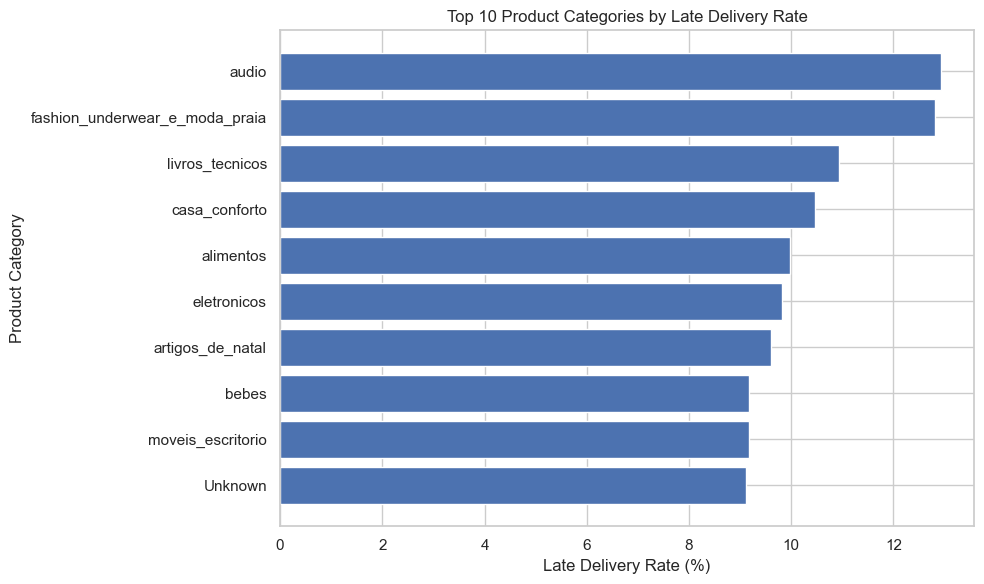

In [18]:
top_categories = reliable_categories.head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_categories["product_category_name"], top_categories["late_rate"])

plt.title("Top 10 Product Categories by Late Delivery Rate")
plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Product Category")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 7. Late Deliveries by Seller

The same de-duplication applies per (order, seller). Sellers are ranked only
once they have at least 50 delivered orders.

In [19]:
MIN_SELLER_ORDERS = 50

seller_delivery = delivered_orders.merge(
    order_items[["order_id", "seller_id"]],
    on="order_id",
    how="left",
)

seller_orders = seller_delivery[
    ["order_id", "seller_id", "delivery_delay_days"]
].drop_duplicates(subset=["order_id", "seller_id"])

seller_orders["is_late"] = seller_orders["delivery_delay_days"] > 0

seller_performance = (
    seller_orders
    .groupby("seller_id")
    .agg(
        total_orders=("order_id", "nunique"),
        late_orders=("is_late", "sum"),
        average_delay=("delivery_delay_days", "mean"),
    )
    .reset_index()
)

seller_performance["late_rate"] = (
    seller_performance["late_orders"] / seller_performance["total_orders"] * 100
)

reliable_sellers = (
    seller_performance[seller_performance["total_orders"] >= MIN_SELLER_ORDERS]
    .sort_values("late_rate", ascending=False)
)

reliable_sellers.head(10)

,seller_id,total_orders,late_orders,average_delay,late_rate
1000,54965bbe3e4f07ae045b90b0b8541f52,73,22,-2.874650,30.136986
1928,a49928bcdf77c55c6d6e05e09a9b4ca5,96,25,-3.678302,26.041667
2211,beadbee30901a7f61d031b6b686095ad,64,16,-8.751648,25.000000
79,06a2c3af7b3aee5d69171b0e14f0ee87,389,90,-10.657200,23.136247
2365,cac4c8e7b1ca6252d8f20b2fc1a2e4af,74,17,-6.078219,22.972973
1141,6039e27294dc75811c0d8a39069f52c0,63,14,-6.620415,22.222222
323,1ca7077d890b907f89be8c954a02686a,108,24,-5.961806,22.222222
1336,712e6ed8aa4aa1fa65dab41fed5737e4,77,17,-8.419706,22.077922
2720,ea566164622c6b439516ab18062c42cd,50,11,-7.391326,22.000000
2435,d13e50eaa47b4cbe9eb81465865d8cfc,66,14,-3.836211,21.212121


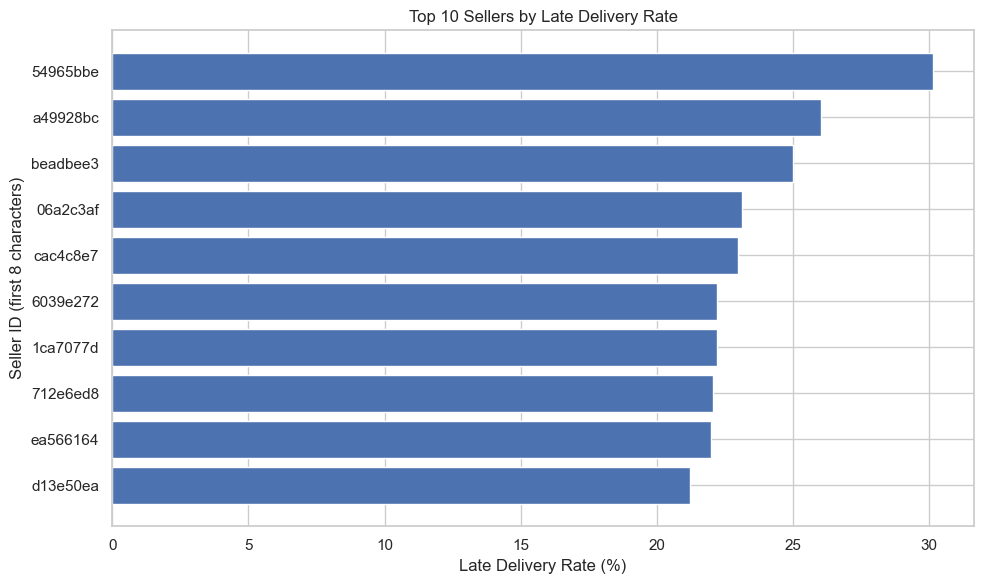

In [20]:
top_sellers = reliable_sellers.head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_sellers["seller_id"].str[:8], top_sellers["late_rate"])

plt.title("Top 10 Sellers by Late Delivery Rate")
plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Seller ID (first 8 characters)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 8. Late Deliveries by Customer State

Delivery reliability by destination state, restricted to states with at least
100 delivered orders.

In [21]:
MIN_STATE_ORDERS = 100

geo_delivery = delivered_orders.merge(
    customers[["customer_id", "customer_city", "customer_state"]],
    on="customer_id",
    how="left",
)

geo_delivery["is_late"] = geo_delivery["delivery_delay_days"] > 0

state_performance = (
    geo_delivery
    .groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        late_orders=("is_late", "sum"),
    )
    .reset_index()
)

state_performance["late_rate"] = (
    state_performance["late_orders"] / state_performance["total_orders"] * 100
)

reliable_states = (
    state_performance[state_performance["total_orders"] >= MIN_STATE_ORDERS]
    .sort_values("late_rate", ascending=False)
)

reliable_states.head(10)

,customer_state,total_orders,late_orders,late_rate
1,AL,397,95,23.929471
9,MA,717,141,19.665272
16,PI,476,76,15.966387
5,CE,1279,196,15.324472
24,SE,335,51,15.223881
4,BA,3256,457,14.035627
18,RJ,12353,1664,13.470412
26,TO,274,35,12.773723
13,PA,946,117,12.367865
7,ES,1995,244,12.230576


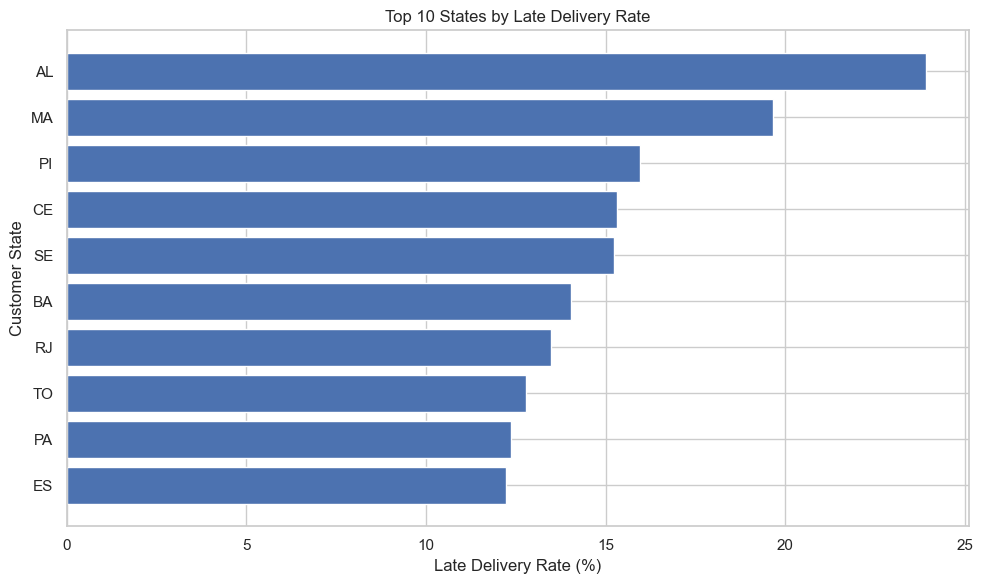

In [22]:
top_states = reliable_states.head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_states["customer_state"], top_states["late_rate"])

plt.title("Top 10 States by Late Delivery Rate")
plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Customer State")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 9. Monthly Late-Delivery Trend

Whether delivery performance improved or degraded over time.

In [23]:
delivered_orders["purchase_month"] = (
    delivered_orders["order_purchase_timestamp"].dt.to_period("M").astype(str)
)

monthly_delivery = (
    delivered_orders
    .groupby("purchase_month")
    .agg(
        total_orders=("order_id", "nunique"),
        late_orders=("delivery_delay_days", lambda x: (x > 0).sum()),
    )
    .reset_index()
)

monthly_delivery["late_rate"] = (
    monthly_delivery["late_orders"] / monthly_delivery["total_orders"] * 100
)

monthly_delivery

,purchase_month,total_orders,late_orders,late_rate
0,2016-09,1,1,100.000000
1,2016-10,270,3,1.111111
2,2016-12,1,0,0.000000
3,2017-01,750,23,3.066667
4,2017-02,1653,53,3.206292
5,2017-03,2546,142,5.577376
6,2017-04,2303,181,7.859314
7,2017-05,3545,128,3.610719
8,2017-06,3135,121,3.859649
9,2017-07,3872,133,3.434917


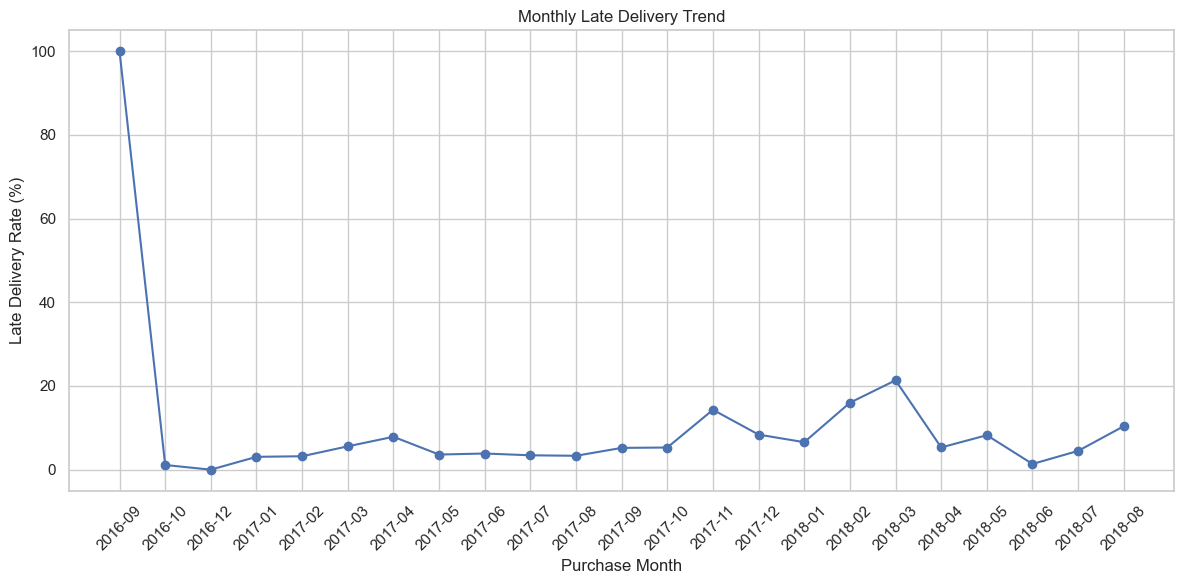

In [24]:
plt.figure(figsize=(12, 6))
plt.plot(monthly_delivery["purchase_month"], monthly_delivery["late_rate"], marker="o")

plt.title("Monthly Late Delivery Trend")
plt.xlabel("Purchase Month")
plt.ylabel("Late Delivery Rate (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## 10. Freight and Order Value vs Delivery Performance

Item prices and freight are aggregated to order level, then compared between
on-time and late deliveries to see whether basket size or shipping cost is
related to missed delivery dates.

In [25]:
order_values = (
    order_items
    .groupby("order_id")
    .agg(
        order_value=("price", "sum"),
        freight_value=("freight_value", "sum"),
    )
    .reset_index()
)

delivery_financials = delivered_orders.merge(order_values, on="order_id", how="left")

delivery_financials["freight_percentage"] = (
    delivery_financials["freight_value"] / delivery_financials["order_value"] * 100
)

delivery_financials[
    ["order_id", "order_value", "freight_value", "freight_percentage"]
].head()

,order_id,order_value,freight_value,freight_percentage
0,e481f51cbdc54678b7cc49136f2d6af7,29.99,8.72,29.076359
1,53cdb2fc8bc7dce0b6741e2150273451,118.70,22.76,19.174389
2,47770eb9100c2d0c44946d9cf07ec65d,159.90,19.22,12.020013
3,949d5b44dbf5de918fe9c16f97b45f8a,45.00,27.20,60.444444
4,ad21c59c0840e6cb83a9ceb5573f8159,19.90,8.72,43.819095


In [26]:
delivery_financials.groupby("on_time_delivery")[
    ["order_value", "freight_value", "freight_percentage"]
].mean()

,order_value,freight_value,freight_percentage
on_time_delivery,,,
False,148.070845,24.622275,31.554559
True,136.064080,22.623264,30.775206


## 11. Customer Purchase Behaviour

Orders are linked to `customer_unique_id` so a returning shopper is recognised
across separate orders.

In [27]:
customer_orders = delivered_orders.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
)

customer_frequency = (
    customer_orders
    .groupby("customer_unique_id")
    .agg(total_orders=("order_id", "nunique"))
    .reset_index()
)

repeat_customer_rate = (
    (customer_frequency["total_orders"] > 1).sum() / len(customer_frequency) * 100
)

print("Unique customers:    ", len(customer_frequency))
print("Repeat customer rate:", round(repeat_customer_rate, 2), "%")

customer_frequency["total_orders"].describe()

Unique customers:     93356
Repeat customer rate: 3.0 %


count    93356.00000
mean         1.03342
std          0.20910
min          1.00000
25%          1.00000
50%          1.00000
75%          1.00000
max         15.00000
Name: total_orders, dtype: float64

In [28]:
customer_spending = customer_orders.merge(order_values, on="order_id", how="left")

customer_spending_summary = (
    customer_spending
    .groupby("customer_unique_id")
    .agg(
        total_spending=("order_value", "sum"),
        total_orders=("order_id", "nunique"),
    )
    .reset_index()
)

customer_spending_summary.sort_values("total_spending", ascending=False).head(10)

,customer_unique_id,total_spending,total_orders
3724,0a0a92112bd4c708ca5fde585afaa872,13440.0,1
79634,da122df9eeddfedc1dc1f5349a1a690c,7388.0,2
43166,763c8b1c9c68a0229c42c9fc6f662b93,7160.0,1
80461,dc4802a71eae9be1dd28f5d788ceb526,6735.0,1
25432,459bef486812aa25204be022145caa62,6729.0,1
93079,ff4159b92c40ebe40454e3e6a7c35ed6,6499.0,1
23407,4007669dec559734d6f53e029e360987,5934.6,1
87145,eebb5dda148d3893cdaf5b5ca3040ccb,4690.0,1
26636,48e1ac109decbb87765a3eade6854098,4590.0,1
59161,a229eba70ec1c2abef51f04987deb7a5,4400.0,1


## 12. Summary of Findings

Headline delivery metrics, followed by the ranked tables that drive the
recommendations: which categories, sellers, states and months carry the highest
share of late deliveries.

In [29]:
total_delivered = len(delivered_orders)
on_time_orders = int(delivered_orders["on_time_delivery"].sum())
late_orders = len(late_deliveries)

print("Total delivered orders:         ", total_delivered)
print("On-time delivery rate:          ",
      round(on_time_orders / total_delivered * 100, 2), "%")
print("Late delivery rate:             ",
      round(late_orders / total_delivered * 100, 2), "%")
print("Average delay among late orders:",
      round(late_deliveries["delivery_delay_days"].mean(), 2), "days")
print("Repeat customer rate:           ", round(repeat_customer_rate, 2), "%")

Total delivered orders:          96476
On-time delivery rate:           91.89 %
Late delivery rate:              8.11 %
Average delay among late orders: 9.55 days
Repeat customer rate:            3.0 %


In [30]:
for label, table in [
    ("Worst 5 product categories by late delivery rate", reliable_categories.head(5)),
    ("Worst 5 sellers by late delivery rate", reliable_sellers.head(5)),
    ("Worst 5 states by late delivery rate", reliable_states.head(5)),
    ("Worst 5 months by late delivery rate",
     monthly_delivery.sort_values("late_rate", ascending=False).head(5)),
]:
    print(label)
    display(table)

Worst 5 product categories by late delivery rate


,product_category_name,total_orders,late_orders,late_rate
8,audio,348,45,12.931034
40,fashion_underwear_e_moda_praia,117,15,12.820513
50,livros_tecnicos,256,28,10.937500
15,casa_conforto,392,41,10.459184
2,alimentos,441,44,9.977324


Worst 5 sellers by late delivery rate


,seller_id,total_orders,late_orders,average_delay,late_rate
1000,54965bbe3e4f07ae045b90b0b8541f52,73,22,-2.874650,30.136986
1928,a49928bcdf77c55c6d6e05e09a9b4ca5,96,25,-3.678302,26.041667
2211,beadbee30901a7f61d031b6b686095ad,64,16,-8.751648,25.000000
79,06a2c3af7b3aee5d69171b0e14f0ee87,389,90,-10.657200,23.136247
2365,cac4c8e7b1ca6252d8f20b2fc1a2e4af,74,17,-6.078219,22.972973


Worst 5 states by late delivery rate


,customer_state,total_orders,late_orders,late_rate
1,AL,397,95,23.929471
9,MA,717,141,19.665272
16,PI,476,76,15.966387
5,CE,1279,196,15.324472
24,SE,335,51,15.223881


Worst 5 months by late delivery rate


,purchase_month,total_orders,late_orders,late_rate
0,2016-09,1,1,100.000000
17,2018-03,7003,1496,21.362273
16,2018-02,6556,1049,16.000610
13,2017-11,7288,1043,14.311196
22,2018-08,6351,660,10.392064
